# 02 · Thuật toán DBSCAN

**Nguyên Khang** · Phân cụm mật độ trên tám đặc trưng, 2.315 quốc gia–năm. Gồm mô hình mô tả toàn panel và thí nghiệm train/validation/test tách theo quốc gia.

## 1. Giới thiệu thuật toán DBSCAN

DBSCAN tìm các vùng có mật độ cao, cho phép hình dạng cụm không lồi và không yêu cầu đặt số cụm trước. Điểm không được nhận vào cụm mang nhãn -1. Bài toán không có nhãn kinh tế đúng chuẩn; do đó không tính accuracy, precision hay recall như phân loại có giám sát.

Nghiên cứu kiểm tra hai vấn đề: triển khai thuật toán có đúng hay không và cấu trúc cụm có đủ rõ, ổn định, độ phủ cao hay không. Hai vấn đề này được đánh giá riêng.

In [1]:
from collections import deque
from pathlib import Path
import hashlib
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs, make_moons
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, RobustScaler

SEED = 42
KEYS = ["country", "year"]
ROOT = Path.cwd().resolve()
while not (ROOT / "du_lieu").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Hãy mở notebook trong repo DBSCAN.")
    ROOT = ROOT.parent
FIG = ROOT / "Khang/bieu_do"
OUT = ROOT / "ket_qua_chung/dbscan"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 16)
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__)

Python 3.12.9 | scikit-learn 1.9.1


In [2]:
paths = {
    "clean": ROOT / "du_lieu/du_lieu_sach/wdi_clean.csv",
    "scaled": ROOT / "du_lieu/du_lieu_chuan_hoa/wdi_scaled.csv",
    "metadata": ROOT / "du_lieu/du_lieu_chuan_hoa/preprocessing_metadata.json",
}
missing = [str(p.relative_to(ROOT)) for p in paths.values() if not p.is_file()]
if missing:
    raise FileNotFoundError("Chạy notebook 01 trước. Thiếu: " + ", ".join(missing))
meta = json.loads(paths["metadata"].read_text(encoding="utf-8"))
features = meta["feature_columns"]
clean = pd.read_csv(paths["clean"]).sort_values(KEYS).reset_index(drop=True)
data = pd.read_csv(paths["scaled"]).sort_values(KEYS).reset_index(drop=True)
for name in ["clean", "scaled"]:
    raw = paths[name].read_bytes()
    actual = hashlib.sha256(raw).hexdigest()
    expected = meta["outputs"][name + "_sha256"]
    assert actual == expected, f"Sai checksum {name}; chạy lại notebook 01."
assert len(features) == len(set(features)) and not set(KEYS) & set(features)
assert not clean.duplicated(KEYS).any() and not data.duplicated(KEYS).any()
assert not data[KEYS].isna().any().any() and clean["is_aggregate"].eq(0).all()
assert clean[KEYS].equals(data[KEYS])
X = data[features].to_numpy(dtype=float)
assert X.shape[0] > 24 and np.isfinite(X).all()
print(f"{len(data):,} quan sát | {data.country.nunique()} nền kinh tế | "
      f"{data.year.min()}–{data.year.max()} | {X.shape[1]} đặc trưng")
display(data.groupby("year").size().rename("n_samples").to_frame().T)

2,315 quan sát | 162 nền kinh tế | 2010–2024 | 8 đặc trưng


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
n_samples,154,153,152,153,155,156,156,155,156,156,156,156,155,151,151


## 2. Cơ sở lý thuyết và nguyên lý hoạt động

Với p đặc trưng đã chuẩn hóa, khoảng cách Euclidean và lân cận được xác định bởi:

$$d(x_i,x_j)=\sqrt{\sum_{r=1}^{p}(x_{ir}-x_{jr})^2},\qquad
N_\varepsilon(x_i)=\{x_j:d(x_i,x_j)\leq\varepsilon\}.$$

Thuật toán duyệt điểm chưa xét, mở cụm từ điểm lõi và tiếp tục qua những điểm lõi liên thông. Điểm biên được nhận vào cụm nhưng không mở rộng cụm. Một điểm tạm mang nhãn noise có thể trở thành border khi được một core nhận vào sau đó.

Bản tự viết tìm lân cận khi cần, có thời gian O(n²p), không cấp phát ma trận khoảng cách n×n. Đây là triển khai phục vụ đồ án, chưa tối ưu cho dữ liệu lớn.

## 3. Giải thích eps và min_samples

eps là bán kính trong không gian đã chuẩn hóa; min_samples là số điểm cần có trong lân cận, **bao gồm chính điểm đang xét**. eps lớn có thể nối các nhóm; min_samples lớn yêu cầu mật độ cao hơn. eps không giới hạn đường kính toàn cụm.

Khảo sát min_samples = 5, 8, 12, 16, 24 và eps theo K-distance. Cùng một eps không tương đương khi đổi thang đo hoặc số lượng mẫu.

## 4. Phân biệt Core Point, Border Point và Noise Point

| Loại | Điều kiện | Vai trò |
| --- | --- | --- |
| Core | Lân cận có ít nhất min_samples điểm | Tiếp tục mở rộng cụm |
| Border | Không đủ mật độ nhưng nằm trong lân cận core | Thuộc cụm, không mở rộng |
| Noise | Không được gán vào cụm sau khi duyệt xong | Nhãn -1 |

Số nhãn 0, 1, 2... không thể hiện thứ hạng kinh tế. Border gần hai cụm có thể được gán khác khi đổi thứ tự duyệt; các core liên thông và tập noise không đổi do riêng việc đổi thứ tự.

## 5. Xây dựng DBSCAN from scratch

`visited` lưu trạng thái đã kiểm tra mật độ, `labels` lưu nhãn và `core` lưu mặt nạ điểm lõi. Hàng đợi mở rộng vùng mật độ; `queued` tránh đưa lặp điểm vào hàng đợi của cùng cụm. Phần thuật toán chỉ dùng NumPy và deque, không gọi DBSCAN của thư viện.

In [3]:
def dbscan_from_scratch(points, eps=0.5, min_samples=5):
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or 0 in points.shape or not np.isfinite(points).all():
        raise ValueError("points phải là bảng số 2D không rỗng, không NaN/inf.")
    if not np.isfinite(eps) or eps <= 0:
        raise ValueError("eps phải hữu hạn và lớn hơn 0.")
    if isinstance(min_samples, (bool, np.bool_)) or not isinstance(min_samples, (int, np.integer)) or min_samples < 1:
        raise ValueError("min_samples phải là số nguyên dương.")
    labels = np.full(len(points), -1, dtype=int)
    visited = np.zeros(len(points), dtype=bool)
    core = np.zeros(len(points), dtype=bool)
    cluster = 0

    def neighbors(i):
        return np.flatnonzero(np.linalg.norm(points - points[i], axis=1) <= eps)

    for i in range(len(points)):
        if visited[i]:
            continue
        visited[i] = True
        seeds = neighbors(i)
        if len(seeds) < min_samples:
            continue
        core[i], labels[i] = True, cluster
        queue = deque(seeds.tolist())
        queued = np.zeros(len(points), dtype=bool)
        queued[seeds] = True
        while queue:
            j = queue.popleft()
            if not visited[j]:
                visited[j] = True
                nearby = neighbors(j)
                if len(nearby) >= min_samples:
                    core[j] = True
                    queue.extend(nearby[~queued[nearby]].tolist())
                    queued[nearby] = True
            if labels[j] == -1:
                labels[j] = cluster
        cluster += 1
    return labels, core

## 6. Kiểm thử thuật toán trên dữ liệu giả lập

Tám trường hợp có đáp án biết trước bao gồm một cụm, toàn noise, điểm trùng, biên bằng eps, noise trở thành border, border không lan cụm, một điểm và min_samples lớn hơn số mẫu. Mười một trường hợp đầu vào sai kiểm tra bảng rỗng, sai số chiều, NaN/inf và tham số không hợp lệ. Dữ liệu giả lập không được trộn với WDI.

In [4]:
cases = [
    ("Một cụm", [[0], [0.1], [0.2]], 0.3, 3, [0, 0, 0], [1, 1, 1]),
    ("Toàn noise", [[0], [2], [4]], 0.1, 2, [-1, -1, -1], [0, 0, 0]),
    ("Điểm trùng", [[0], [0], [0], [3]], 0.1, 3, [0, 0, 0, -1], [1, 1, 1, 0]),
    ("Đúng biên eps", [[0], [1], [2]], 1.0, 2, [0, 0, 0], [1, 1, 1]),
    ("Noise thành border", [[0], [0.8], [1], [1.2]], 0.9, 3,
     [0, 0, 0, 0], [0, 1, 1, 1]),
    ("Border không lan", [[0], [0.1], [0.2], [0.3], [1.2], [2.1]], 0.95, 4,
     [0, 0, 0, 0, 0, -1], [1, 1, 1, 1, 0, 0]),
    ("Một điểm, min=1", [[0]], 0.1, 1, [0], [1]),
    ("min_samples > n", [[0], [0]], 0.1, 3, [-1, -1], [0, 0]),
]
for name, points, eps, m, expected, expected_core in cases:
    labels, core = dbscan_from_scratch(points, eps, m)
    np.testing.assert_array_equal(labels, expected, err_msg=name)
    np.testing.assert_array_equal(core, expected_core, err_msg=name)
print(f"PASS: {len(cases)} ca có đáp án biết trước.")

PASS: 8 ca có đáp án biết trước.


In [5]:
invalid = [([], 0.5, 2), ([1, 2], 0.5, 2), ([[np.nan]], 0.5, 2),
           ([[np.inf]], 0.5, 2), ([[0]], 0, 2), ([[0]], -1, 2),
           ([[0]], np.nan, 2), ([[0]], np.inf, 2),
           ([[0]], 0.5, 0), ([[0]], 0.5, 1.5), ([[0]], 0.5, True)]
for points, eps, m in invalid:
    try:
        dbscan_from_scratch(points, eps, m)
    except ValueError:
        continue
    raise AssertionError("Hàm chưa từ chối đầu vào không hợp lệ.")
print(f"PASS: {len(invalid)} ca đầu vào không hợp lệ.")

PASS: 11 ca đầu vào không hợp lệ.


## 7. Đối chiếu với DBSCAN của scikit-learn

Đối chiếu 36 cấu hình blobs/moons trên cùng dữ liệu, thứ tự và tham số. ARI kiểm tra phân hoạch mà không phụ thuộc số nhãn; mặt nạ core/noise được kiểm tra riêng. Kết quả ARI = 1 và khớp core/noise ở các trường hợp này xác nhận sự thống nhất hai triển khai, **không phải độ chính xác kinh tế 100%**.

In [6]:
def compare_with_sklearn(points, eps, m):
    labels, core = dbscan_from_scratch(points, eps, m)
    reference = DBSCAN(eps=eps, min_samples=m, algorithm="brute").fit(points)
    reference_core = np.zeros(len(points), dtype=bool)
    reference_core[reference.core_sample_indices_] = True
    np.testing.assert_array_equal(core, reference_core)
    np.testing.assert_array_equal(labels == -1, reference.labels_ == -1)
    ari = adjusted_rand_score(labels, reference.labels_)
    assert ari == 1.0, "Hai triển khai chưa cho cùng phân hoạch."
    return labels, core, ari

comparison = []
for seed in range(3):
    examples = {"blobs": make_blobs(n_samples=120, centers=3, cluster_std=0.3,
                                   random_state=seed)[0],
                "moons": make_moons(n_samples=120, noise=0.04, random_state=seed)[0]}
    for name, points in examples.items():
        for eps in [0.15, 0.3, 0.6]:
            for m in [3, 5]:
                _, _, ari = compare_with_sklearn(points, eps, m)
                comparison.append({"dataset": name, "seed": seed,
                                   "eps": eps, "min_samples": m, "ari": ari})
comparison = pd.DataFrame(comparison)
print(f"PASS: {len(comparison)} cấu hình blobs/moons, ARI = 1 và khớp core/noise.")

PASS: 36 cấu hình blobs/moons, ARI = 1 và khớp core/noise.


### Thứ tự duyệt

Border giữa hai cụm có thể đổi cụm khi đảo thứ tự; phân hoạch core và tập noise phải giữ nguyên.

PASS: core/noise ổn định; border ở giữa có thể thuộc cụm khác khi đảo thứ tự.


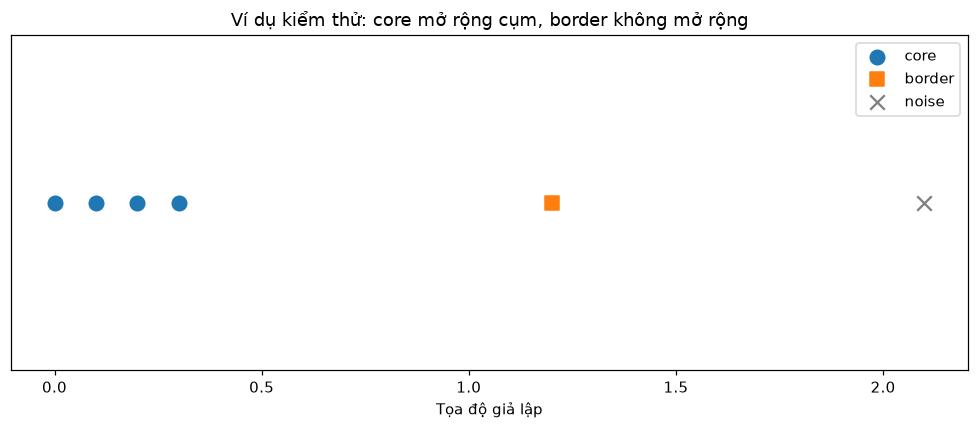

In [7]:
ambiguous = np.array([-1.4, -1.3, -1.2, -0.9, 0.9, 1.2, 1.3, 1.4, 0])[:, None]
a, core_a = dbscan_from_scratch(ambiguous, 1.0, 4)
b, core_b = dbscan_from_scratch(ambiguous[::-1], 1.0, 4)
b, core_b = b[::-1], core_b[::-1]
np.testing.assert_array_equal(core_a, core_b)
np.testing.assert_array_equal(a == -1, b == -1)
assert adjusted_rand_score(a[core_a], b[core_a]) == 1
compare_with_sklearn(ambiguous, 1.0, 4)
print("PASS: core/noise ổn định; border ở giữa có thể thuộc cụm khác khi đảo thứ tự.")
points = np.array([0, 0.1, 0.2, 0.3, 1.2, 2.1])[:, None]
y_demo, core_demo = dbscan_from_scratch(points, 0.95, 4)
types_demo = np.where(y_demo < 0, "noise", np.where(core_demo, "core", "border"))
for kind, color, marker in [("core", "tab:blue", "o"), ("border", "tab:orange", "s"),
                            ("noise", "gray", "x")]:
    mask = types_demo == kind
    plt.scatter(points[mask, 0], np.zeros(mask.sum()), c=color, marker=marker,
                s=90, label=kind)
plt.title("Ví dụ kiểm thử: core mở rộng cụm, border không mở rộng")
plt.xlabel("Tọa độ giả lập"); plt.yticks([]); plt.legend(); plt.tight_layout()
plt.savefig(FIG / "01_core_border_noise.png"); plt.show()

## 8. Phân tích K-distance để lựa chọn eps

Truy vấn `kneighbors(X)` để tính cả chính điểm đang xét, phù hợp quy ước min_samples. Mỗi đường K-distance sinh 18 eps từ phân vị 10% đến 95%, làm tròn ba chữ số, tổng cộng 90 cấu hình.

Đường cong tăng dần nhưng không cung cấp một điểm gãy rõ ràng duy nhất. Đồ thị giới hạn trục Y ở phân vị 97% để nhìn vùng chính; tính toán vẫn giữ mọi điểm. Cách chọn tham số này là tìm kiếm hữu hạn, không bảo đảm tối ưu toàn cục.

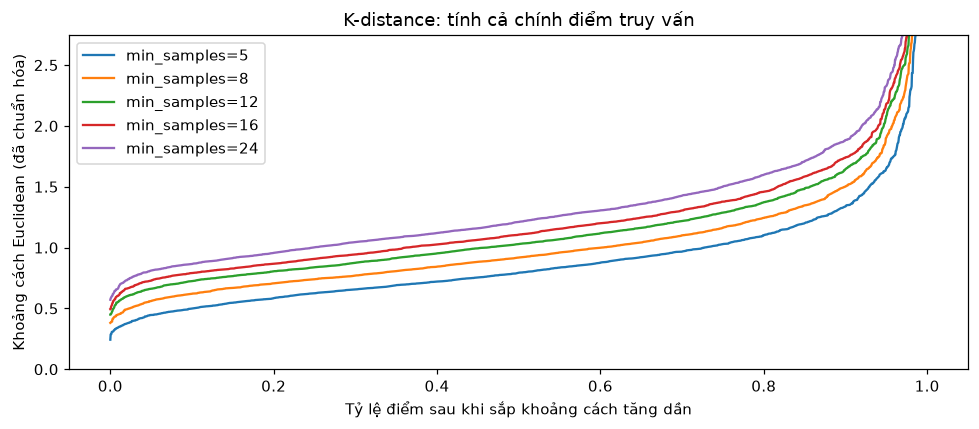

In [8]:
min_samples_grid = [5, 8, 12, 16, 24]
k_distances = {}
for m in min_samples_grid:
    distances = NearestNeighbors(n_neighbors=m).fit(X).kneighbors(X)[0][:, -1]
    k_distances[m] = np.sort(distances)
    plt.plot(np.linspace(0, 1, len(X)), k_distances[m], label=f"min_samples={m}")
plt.ylim(0, max(np.quantile(d, 0.97) for d in k_distances.values()))
plt.xlabel("Tỷ lệ điểm sau khi sắp khoảng cách tăng dần")
plt.ylabel("Khoảng cách Euclidean (đã chuẩn hóa)")
plt.title("K-distance: tính cả chính điểm truy vấn")
plt.legend(); plt.tight_layout()
plt.savefig(FIG / "02_k_distance.png"); plt.show()

## 9. Thực hiện Grid Search

Grid Search giữ nguyên tám biến và mẫu quan sát. Với từng cấu hình, lưu độ phủ, noise, số cụm không kể noise, kích thước cụm lớn nhất/nhỏ nhất, số quốc gia ít nhất mỗi cụm và các chỉ số nội bộ trên non-noise.

Silhouette cao có thể đi kèm độ phủ thấp hoặc một cụm rất lớn và một cụm nhỏ chỉ chứa nhiều năm của một quốc gia. Vì vậy không xếp hạng từ Silhouette đơn lẻ. Các chỉ số không đủ điều kiện có giá trị thiếu kèm lý do, không thay bằng 0.

In [9]:
def cluster_stats(points, labels):
    keep = labels >= 0
    counts = np.unique(labels[keep], return_counts=True)[1]
    valid = 2 <= len(counts) < keep.sum()
    return {
        "n_samples": len(labels), "n_clusters": len(counts),
        "n_clustered": int(keep.sum()), "n_noise": int((~keep).sum()),
        "coverage": float(keep.mean()), "noise_ratio": float((~keep).mean()),
        "smallest_cluster": int(counts.min()) if len(counts) else 0,
        "largest_cluster_ratio": float(counts.max() / keep.sum()) if len(counts) else 0,
        "silhouette": float(silhouette_score(points[keep], labels[keep])) if valid else np.nan,
        "davies_bouldin": float(davies_bouldin_score(points[keep], labels[keep])) if valid else np.nan,
        "calinski_harabasz": float(calinski_harabasz_score(points[keep], labels[keep])) if valid else np.nan,
        "metric_note": "non-noise, full sample" if valid else "N/A: cần 2 <= số cụm < số điểm",
    }

grid_rows = []
for m in min_samples_grid:
    eps_values = np.unique(np.round(np.quantile(k_distances[m], np.linspace(0.1, 0.95, 18)), 3))
    for eps in eps_values:
        labels = DBSCAN(eps=float(eps), min_samples=m).fit_predict(X)
        support = pd.DataFrame({"country": data.country, "cluster": labels})
        support = support[support.cluster >= 0].groupby("cluster").country.nunique()
        grid_rows.append({"run_id": f"m{m}_eps{eps:.3f}", "eps": float(eps),
                          "min_samples": m, "min_countries": int(support.min()) if len(support) else 0,
                          **cluster_stats(X, labels)})
grid = pd.DataFrame(grid_rows).assign(fit_scope="global_panel",
    year_min=int(data.year.min()), year_max=int(data.year.max()))
print(f"Đã khảo sát {len(grid)} cấu hình trên đúng cùng {len(X)} quan sát.")

Đã khảo sát 90 cấu hình trên đúng cùng 2315 quan sát.


## 10. Lựa chọn tham số tối ưu

Điều kiện cơ bản: 2–10 cụm, mỗi cụm ít nhất ba quốc gia, cụm lớn nhất không quá 90% non-noise. Trong các cấu hình đạt độ phủ 65%, ưu tiên Silhouette. Nếu không đạt độ phủ, chọn độ phủ cao nhất trước Silhouette và chỉ xem là thăm dò. Các ngưỡng là tiêu chí nghiên cứu, không phải định lý về DBSCAN.

Trong 90 cấu hình toàn panel, chỉ hai cấu hình đạt điều kiện cơ bản và không cấu hình nào đạt độ phủ 65%. Phương án được chọn là eps = 0,865, min_samples = 24. Cấu hình eps = 1,338, min_samples = 5 phủ 93,91% nhưng cụm lớn chiếm 99,68% non-noise, nên không cung cấp phân chia quốc gia cân đối theo tiêu chí đã đặt.

In [10]:
eligible = grid[grid.n_clusters.between(2, 10) & (grid.min_countries >= 3)
                & (grid.largest_cluster_ratio <= 0.9) & grid.silhouette.notna()]
if eligible.empty:
    raise ValueError("Không có cấu hình thăm dò phù hợp; xem lại lưới, không xuất nhãn giả.")
quality_target_met = bool((eligible.coverage >= 0.65).any())
pool = eligible[eligible.coverage >= 0.65] if quality_target_met else eligible
ranking = ["silhouette", "coverage"] if quality_target_met else ["coverage", "silhouette"]
best = pool.sort_values(ranking + ["eps", "min_samples"],
                        ascending=[False, False, True, True]).iloc[0]
EPS, MIN_SAMPLES = float(best.eps), int(best.min_samples)
print(f"Chọn eps={EPS}, min_samples={MIN_SAMPLES}; đạt mục tiêu độ phủ: {quality_target_met}")
display(pool.sort_values(ranking, ascending=False).head(5).round(4))

Chọn eps=0.865, min_samples=24; đạt mục tiêu độ phủ: False


,run_id,eps,min_samples,min_countries,n_samples,n_clusters,n_clustered,n_noise,...,largest_cluster_ratio,silhouette,davies_bouldin,calinski_harabasz,metric_note,fit_scope,year_min,year_max
72,m24_eps0.865,0.865,24,3,2315,4,759,1556,...,0.8274,0.1889,0.9772,106.8101,"non-noise, full sample",global_panel,2010,2024
54,m16_eps0.791,0.791,16,5,2315,3,663,1652,...,0.8462,0.2752,0.9700,134.5749,"non-noise, full sample",global_panel,2010,2024


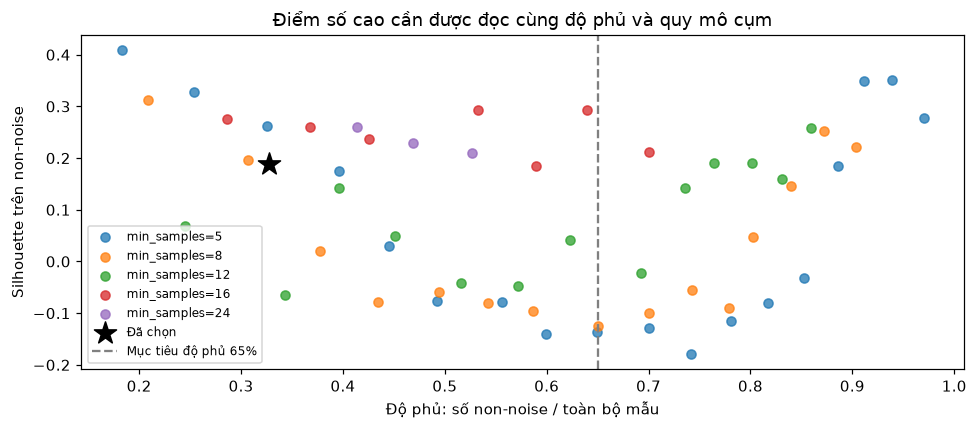

In [11]:
valid_grid = grid.dropna(subset=["silhouette"])
for m, group in valid_grid.groupby("min_samples"):
    plt.scatter(group.coverage, group.silhouette, label=f"min_samples={m}", alpha=0.75)
plt.scatter(best.coverage, best.silhouette, marker="*", s=230, c="black", label="Đã chọn")
plt.axvline(0.65, color="gray", linestyle="--", label="Mục tiêu độ phủ 65%")
plt.xlabel("Độ phủ: số non-noise / toàn bộ mẫu"); plt.ylabel("Silhouette trên non-noise")
plt.title("Điểm số cao cần được đọc cùng độ phủ và quy mô cụm")
plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(FIG / "03_grid_search.png"); plt.show()

## 11. Chạy DBSCAN trên dữ liệu thực tế

Bản tự viết được kiểm chứng với scikit-learn trên toàn bộ 2.315 điểm: ARI = 1 và mặt nạ core/noise khớp. Mô hình tạo bốn cụm với 759 non-noise (32,79%) và 1.556 noise (67,21%). Silhouette non-noise 0,1889 cho thấy độ tách cụm còn hạn chế.

Cụm lớn nhất chứa 628 điểm, tương đương 82,74% non-noise; các cụm còn lại chỉ có 89, 24 và 18 điểm. Cấu trúc mất cân đối này và tỷ lệ noise cao hạn chế khả năng diễn giải mô hình như một hệ phân loại chung cho mọi nền kinh tế. PCA chỉ để vẽ; mô hình fit trên đủ tám biến.

In [12]:
labels, core, real_ari = compare_with_sklearn(X, EPS, MIN_SAMPLES)
point_type = np.where(labels < 0, "noise", np.where(core, "core", "border"))
result = data[KEYS].assign(cluster=labels, point_type=point_type)
final_summary = cluster_stats(X, labels)
cluster_sizes = result.groupby("cluster").agg(
    n_samples=("country", "size"), n_countries=("country", "nunique"))
print("PASS: WDI thật khớp scikit-learn về phân hoạch, core và noise.")
display(pd.DataFrame([final_summary]).round(4))
display(cluster_sizes)
display(result.point_type.value_counts().rename("n_samples").to_frame())

PASS: WDI thật khớp scikit-learn về phân hoạch, core và noise.


,n_samples,n_clusters,n_clustered,n_noise,coverage,noise_ratio,smallest_cluster,largest_cluster_ratio,silhouette,davies_bouldin,calinski_harabasz,metric_note
0,2315,4,759,1556,0.3279,0.6721,18,0.8274,0.1889,0.9772,106.8101,"non-noise, full sample"


,n_samples,n_countries
cluster,,
-1,1556,157
0,628,80
1,89,15
2,24,4
3,18,3


,n_samples
point_type,
noise,1556
border,527
core,232


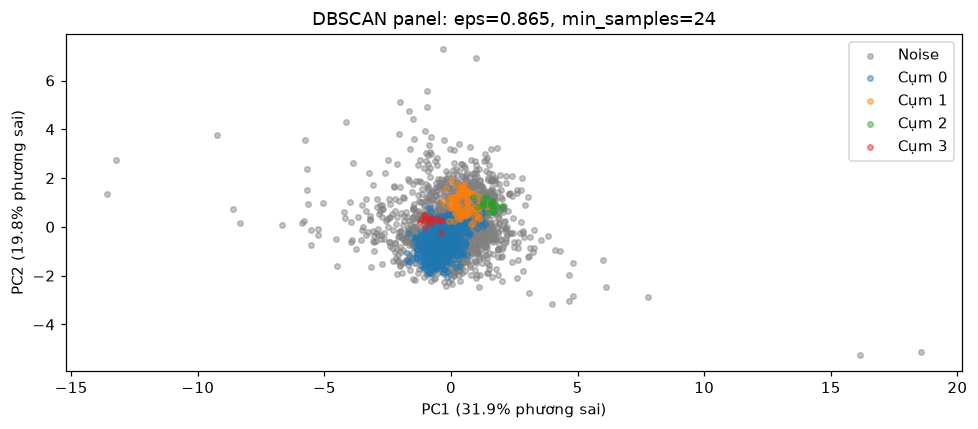

In [13]:
pca = PCA(n_components=2)
projection = pca.fit_transform(X)
for cluster in np.unique(labels):
    mask = labels == cluster
    plt.scatter(projection[mask, 0], projection[mask, 1], s=13, alpha=0.45,
                color="gray" if cluster == -1 else None,
                label="Noise" if cluster == -1 else f"Cụm {cluster}")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} phương sai)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} phương sai)")
plt.title(f"DBSCAN panel: eps={EPS}, min_samples={MIN_SAMPLES}")
plt.legend(); plt.tight_layout()
plt.savefig(FIG / "04_dbscan_pca.png"); plt.show()

## 12. Kiểm tra độ nhạy và độ ổn định

Khảo sát eps ±10% và min_samples ±20% làm tỷ lệ noise thay đổi từ 49,42% đến 91,19%; số cụm từ hai tới năm. Mô hình nhạy với mật độ, chưa có bằng chứng ổn định theo một vùng tham số rộng.

Năm seed được dùng cho đảo thứ tự, nhiễu Gaussian σ = 0,01 trên thang chuẩn hóa và lấy 80% quốc gia. ARI toàn bộ điểm có thể được nâng bởi tập noise lớn; bổ sung ARI trên giao các điểm non-noise và số điểm của giao này để đọc cùng noise Jaccard. Lấy mẫu theo quốc gia, không coi từng năm là một mẫu độc lập.

,eps,min_samples,n_clusters,noise_ratio,ari
0,0.7785,19,5,0.7840,0.5842
1,0.7785,24,2,0.8661,0.3393
2,0.7785,29,2,0.9119,0.2123
3,0.8650,19,2,0.6207,0.7630
4,0.8650,24,4,0.6721,1.0000
5,0.8650,29,2,0.7512,0.7335
6,0.9515,19,2,0.4942,0.3737
7,0.9515,24,2,0.5330,0.4822
8,0.9515,29,2,0.5771,0.5986


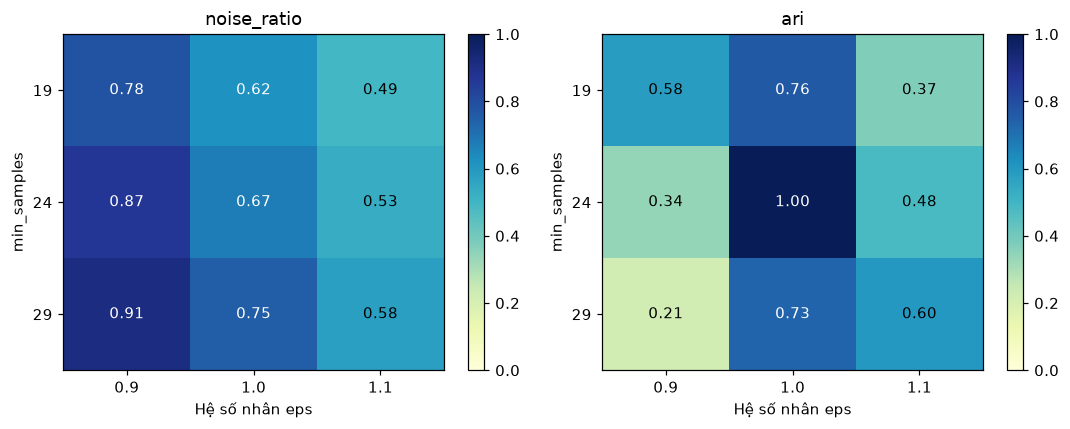

In [14]:
sensitivity_rows = []
for factor in [0.9, 1.0, 1.1]:
    for m in sorted({max(2, round(MIN_SAMPLES * f)) for f in [0.8, 1.0, 1.2]}):
        eps = round(EPS * factor, 6)
        changed = DBSCAN(eps=eps, min_samples=m).fit_predict(X)
        sensitivity_rows.append({"eps_factor": factor, "eps": eps, "min_samples": m,
                                 "ari": adjusted_rand_score(labels, changed),
                                 **cluster_stats(X, changed)})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity[["eps", "min_samples", "n_clusters", "noise_ratio", "ari"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ["noise_ratio", "ari"]):
    table = sensitivity.pivot(index="min_samples", columns="eps_factor", values=metric)
    image = ax.imshow(table, vmin=0, vmax=1, cmap="YlGnBu", aspect="auto")
    ax.set(xticks=range(len(table.columns)), xticklabels=table.columns,
           yticks=range(len(table.index)), yticklabels=table.index,
           xlabel="Hệ số nhân eps", ylabel="min_samples", title=metric)
    for (i, j), value in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if value > 0.6 else "black")
    fig.colorbar(image, ax=ax)
fig.tight_layout(); fig.savefig(FIG / "05_do_nhay.png"); plt.show()

### Độ ổn định

Đảo thứ tự cho ARI = 1 và noise Jaccard = 1 ở cả năm seed. Khi thêm nhiễu nhỏ, ARI toàn mẫu trung bình 0,9269 nhưng ARI trên giao non-noise có mức thấp nhất 0,2514; phần cụm vẫn có thể đổi đáng kể dù tập noise gần như giữ nguyên. Lấy 80% quốc gia cho ARI toàn mẫu trung bình 0,8319.

ARI trên giao non-noise cũng chỉ phản ánh các điểm còn được gán ở cả hai lần: phải đọc cùng `n_common_non_noise` và độ phủ, không xem là điểm ổn định của toàn bộ mẫu.

In [15]:
stability_rows = []
for seed in range(5):
    rng = np.random.default_rng(SEED + seed)
    chosen_countries = rng.choice(data.country.unique(),
                                  size=round(data.country.nunique() * 0.8), replace=False)
    subset = np.flatnonzero(data.country.isin(chosen_countries))
    experiments = [("shuffle", rng.permutation(len(X)), None),
                   ("jitter", np.arange(len(X)), rng.normal(0, 0.01, X.shape)),
                   ("country_80pct", subset, None)]
    for kind, indices, jitter in experiments:
        points = X[indices] if jitter is None else X[indices] + jitter[indices]
        changed = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(points)
        before_noise, after_noise = labels[indices] < 0, changed < 0
        union = (before_noise | after_noise).sum()
        common = ~(before_noise | after_noise)
        common_ari = adjusted_rand_score(labels[indices][common], changed[common]) if common.sum() > 1 else np.nan
        stability_rows.append({"test": kind, "seed": SEED + seed,
                               "ari": adjusted_rand_score(labels[indices], changed),
                               "ari_common_non_noise": common_ari, "n_common_non_noise": int(common.sum()),
                               "noise_jaccard": float((before_noise & after_noise).sum() / union) if union else 1.0,
                               **cluster_stats(points, changed)})
stability = pd.DataFrame(stability_rows)
display(stability.groupby("test")[["ari", "ari_common_non_noise", "noise_jaccard", "coverage"]].agg(["mean", "min"]).round(4))
assert np.allclose(stability.loc[stability.test == "shuffle", "noise_jaccard"], 1)

ari         ari_common_non_noise         noise_jaccard  \
                 mean     min                 mean     min          mean   
test                                                                       
country_80pct  0.8319  0.7775               0.9712  0.9502        0.9327   
jitter         0.9269  0.8858               0.8447  0.2514        0.9711   
shuffle        1.0000  1.0000               1.0000  1.0000        1.0000   

                      coverage          
                  min     mean     min  
test                                    
country_80pct  0.9152   0.2769  0.2403  
jitter         0.9680   0.3177  0.3153  
shuffle        1.0000   0.3279  0.3279

### Thang đo và lát cắt năm

StandardScaler được fit trên ma trận đã biến đổi; eps được hiệu chỉnh theo tỷ lệ trung vị K-distance để có thang khoảng cách phù hợp. Đây là chẩn đoán phụ, không dùng để thay tham số toàn panel sau đánh giá.

Cùng eps/min_samples panel khi fit riêng từng năm cho toàn noise ở cả 15 năm. Điều này cho thấy ngưỡng mật độ không chuyển nguyên sang mẫu theo năm nhỏ hơn; không chứng minh mọi cấu hình DBSCAN theo năm đều thất bại.

In [16]:
standard = StandardScaler().fit_transform(X)
standard_k = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(standard).kneighbors(standard)[0][:, -1]
standard_eps = EPS * np.median(standard_k) / np.median(k_distances[MIN_SAMPLES])
standard_labels = DBSCAN(eps=standard_eps, min_samples=MIN_SAMPLES).fit_predict(standard)
scaling_check = pd.DataFrame([{"scaler": "StandardScaler", "eps": standard_eps,
                               "ari": adjusted_rand_score(labels, standard_labels),
                               **cluster_stats(standard, standard_labels)}])
yearly_rows = []
for year, indices in data.groupby("year").groups.items():
    points = X[indices]
    changed = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(points)
    yearly_rows.append({"year": int(year), **cluster_stats(points, changed)})
yearly_check = pd.DataFrame(yearly_rows)
display(scaling_check.round(4))
display(yearly_check[["year", "n_clusters", "coverage", "silhouette"]].round(4))

,scaler,eps,ari,n_samples,n_clusters,n_clustered,n_noise,coverage,noise_ratio,smallest_cluster,largest_cluster_ratio,silhouette,davies_bouldin,calinski_harabasz,metric_note
0,StandardScaler,1.0183,0.7067,2315,3,704,1611,0.3041,0.6959,24,0.6435,0.2611,1.2142,204.0482,"non-noise, full sample"


,year,n_clusters,coverage,silhouette
0,2010,0,0.0,NaN
1,2011,0,0.0,NaN
2,2012,0,0.0,NaN
3,2013,0,0.0,NaN
4,2014,0,0.0,NaN
5,2015,0,0.0,NaN
6,2016,0,0.0,NaN
7,2017,0,0.0,NaN
8,2018,0,0.0,NaN
9,2019,0,0.0,NaN


### Kiểm định ngoài mẫu: chia theo quốc gia

Thí nghiệm độc lập giữ khoảng 60% quốc gia làm **train**, 20% làm **validation**, 20% làm **test**, seed 42. Tất cả các năm của một quốc gia thuộc cùng một tập; tránh rò rỉ do các năm gần nhau của cùng quốc gia. Phép biến đổi log được cố định theo thiết kế đặc trưng, còn trung vị và IQR của RobustScaler chỉ được fit trên train.

Tiền xử lý thiếu dùng dữ liệu của chính từng quốc gia trong toàn giai đoạn, nên đây là kiểm định chuyển sang **quốc gia chưa thấy trong phân tích hồi cứu**, không phải dự báo tương lai. Đánh giá có điều kiện trên 162 nền kinh tế còn đủ biến; không bao gồm 55 nền kinh tế bị loại do thiếu dữ liệu.

Mô hình DBSCAN không có phương thức predict. Điểm validation/test được gán nhãn của **core train gần nhất** nếu khoảng cách không quá eps; nếu không, gán -1. Không dùng điểm mới để mở rộng hoặc tạo cụm. Quy tắc này là phần mở rộng gán nhãn, không tương đương fit lại DBSCAN trên test.

In [17]:
train_countries, heldout = train_test_split(np.sort(clean.country.unique()), test_size=0.4, random_state=SEED)
validation_countries, test_countries = train_test_split(heldout, test_size=0.5, random_state=SEED)
split = clean[KEYS].copy()
split["split"] = "train"
split.loc[split.country.isin(validation_countries), "split"] = "validation"
split.loc[split.country.isin(test_countries), "split"] = "test"
assert split.groupby("country").split.nunique().eq(1).all()
assert set(train_countries).isdisjoint(heldout)
assert set(validation_countries).isdisjoint(test_countries)
transformed = clean[features].copy()
log_columns = meta["transformations"]["log1p_columns"]
signed_columns = meta["transformations"]["signed_log1p_columns"]
transformed[log_columns] = np.log1p(transformed[log_columns])
transformed[signed_columns] = np.sign(transformed[signed_columns]) * np.log1p(transformed[signed_columns].abs())
train_scaler = RobustScaler().fit(transformed.loc[split.split == "train"])
train_X = train_scaler.transform(transformed.loc[split.split == "train"])
validation_X = train_scaler.transform(transformed.loc[split.split == "validation"])
display(split.groupby("split").agg(n_countries=("country", "nunique"), n_samples=("country", "size")))

,n_countries,n_samples
split,,
test,33,454
train,97,1397
validation,32,464


In [18]:
def assign_to_core(points, core_points, core_labels, eps):
    if len(core_points) == 0:
        return np.full(len(points), -1, dtype=int)
    search = NearestNeighbors(n_neighbors=1).fit(core_points)
    distances, nearest = search.kneighbors(points)
    return np.where(distances[:, 0] <= eps, core_labels[nearest[:, 0]], -1)

assigned = assign_to_core(np.array([[0], [1], [3], [5]]), np.array([[0], [3]]), np.array([0, 1]), 1)
np.testing.assert_array_equal(assigned, [0, 0, 1, -1])
np.testing.assert_array_equal(assign_to_core(np.array([[0]]), np.empty((0, 1)), np.array([]), 1), [-1])
training_grid = []
train_country = clean.loc[split.split == "train", "country"].to_numpy()
for m in min_samples_grid:
    distances = NearestNeighbors(n_neighbors=m).fit(train_X).kneighbors(train_X)[0][:, -1]
    for eps in np.unique(np.round(np.quantile(distances, np.linspace(0.1, 0.95, 18)), 3)):
        model = DBSCAN(eps=float(eps), min_samples=m).fit(train_X)
        train_stats = cluster_stats(train_X, model.labels_)
        assigned = assign_to_core(validation_X, model.components_, model.labels_[model.core_sample_indices_], eps)
        validation_stats = cluster_stats(validation_X, assigned)
        support = pd.DataFrame({"country": train_country, "cluster": model.labels_})
        support = support[support.cluster >= 0].groupby("cluster").country.nunique()
        training_grid.append({"eps": float(eps), "min_samples": m,
            "train_clusters": train_stats["n_clusters"], "train_coverage": train_stats["coverage"],
            "min_countries": int(support.min()) if len(support) else 0,
            "largest_cluster_ratio": train_stats["largest_cluster_ratio"],
            "validation_clusters": validation_stats["n_clusters"],
            "validation_coverage": validation_stats["coverage"],
            "validation_silhouette": validation_stats["silhouette"]})
training_grid = pd.DataFrame(training_grid)

Tham số được chọn bằng validation sau khi loại cấu hình train có dưới 2 hoặc trên 10 cụm, cụm nhỏ hơn 3 quốc gia hoặc cụm lớn nhất chiếm trên 90% non-noise. Nếu có cấu hình đạt độ phủ validation 65%, ưu tiên Silhouette; nếu không, ưu tiên độ phủ rồi Silhouette và ghi nhận không đạt mục tiêu. Test không tham gia lưới, lựa chọn đặc trưng hay quyết định chọn tham số. Tham số của thí nghiệm này độc lập với mô hình mô tả toàn panel.

In [19]:
candidates = training_grid[training_grid.train_clusters.between(2, 10)
    & (training_grid.min_countries >= 3) & (training_grid.largest_cluster_ratio <= 0.9)
    & training_grid.validation_silhouette.notna()]
if candidates.empty:
    raise ValueError("Không có cấu hình train/validation hợp lệ; chưa đánh giá test.")
validation_target_met = bool((candidates.validation_coverage >= 0.65).any())
validation_pool = candidates[candidates.validation_coverage >= 0.65] if validation_target_met else candidates
validation_ranking = (["validation_silhouette", "validation_coverage"] if validation_target_met
                      else ["validation_coverage", "validation_silhouette"])
selected = validation_pool.sort_values(validation_ranking + ["eps", "min_samples"],
                                      ascending=[False, False, True, True]).iloc[0]
train_eps, train_m = float(selected.eps), int(selected.min_samples)
train_labels, train_core, train_ari = compare_with_sklearn(train_X, train_eps, train_m)
test_X = train_scaler.transform(transformed.loc[split.split == "test"])
train_core_points, train_core_labels = train_X[train_core], train_labels[train_core]
heldout_metrics, heldout_predictions = [], []
for name, points in [("train", train_X), ("validation", validation_X), ("test", test_X)]:
    assigned = train_labels if name == "train" else assign_to_core(points, train_core_points, train_core_labels, train_eps)
    heldout_metrics.append({"split": name, "eps": train_eps, "min_samples": train_m,
                           **cluster_stats(points, assigned)})
    heldout_predictions.append(split.loc[split.split == name].assign(cluster=assigned))
heldout_metrics = pd.DataFrame(heldout_metrics)
heldout_predictions = pd.concat(heldout_predictions).sort_index()
display(heldout_metrics[["split", "n_samples", "n_clusters", "coverage", "silhouette", "davies_bouldin", "calinski_harabasz"]])

,split,n_samples,n_clusters,coverage,silhouette,davies_bouldin,calinski_harabasz
0,train,1397,3,0.361489,0.098575,1.179554,77.010267
1,validation,464,2,0.252155,0.183857,1.031847,13.356671
2,test,454,1,0.198238,NaN,NaN,NaN


**Kết quả kiểm định.** Train gồm 1.397 điểm/97 quốc gia, validation 464 điểm/32 quốc gia và test 454 điểm/33 quốc gia. Trong 90 cấu hình, một cấu hình đáp ứng điều kiện train và có Silhouette validation hợp lệ: eps = 0,902, min_samples = 16. Độ phủ train 36,15%, validation 25,22%; mục tiêu validation 65% không đạt.

Test được đánh giá sau khi cố định cấu hình: 90/454 điểm được gán vào cụm (19,82%), 364 điểm bị từ chối (80,18%). Chỉ một nhãn cụm xuất hiện ở 90 điểm được gán, do đó cả Silhouette, Davies–Bouldin và Calinski–Harabasz đều **N/A**. Đây là giới hạn thực nghiệm, không điền 0 hoặc coi 19,82% là accuracy.

Thí nghiệm chưa xác nhận mô hình có thể phân tách nhiều nhóm quốc gia chưa thấy. Cấu hình, phép chia và bộ chuẩn hóa được lưu riêng; kết quả test không được dùng quay lại đổi seed, miền tìm kiếm hoặc tham số.

In [20]:
split.to_csv(OUT / "chia_tap_theo_quoc_gia.csv", index=False, lineterminator="\n")
training_grid.to_csv(OUT / "grid_search_ngoai_mau.csv", index=False, lineterminator="\n")
heldout_metrics.to_csv(OUT / "danh_gia_ngoai_mau.csv", index=False, lineterminator="\n")
heldout_predictions.to_csv(OUT / "nhan_ngoai_mau.csv", index=False, lineterminator="\n")
heldout_config = {
    "split_seed": SEED, "split_unit": "country", "target_ratios": [0.6, 0.2, 0.2],
    "n_countries": split.groupby("split").country.nunique().to_dict(),
    "eps": train_eps, "min_samples": train_m, "selected_using": "validation_only",
    "assignment_rule": "nearest train core within eps, else -1; no cluster expansion",
    "validation_target_met": validation_target_met,
    "selection_rule": {"train_clusters": [2, 10], "min_countries": 3,
        "max_largest_cluster_ratio": 0.9, "target_validation_coverage": 0.65,
        "ranking": validation_ranking, "n_candidates": len(training_grid), "n_eligible": len(candidates)},
    "train_center": dict(zip(features, train_scaler.center_)),
    "train_scale": dict(zip(features, train_scaler.scale_)),
    "feature_columns": features, "train_implementation_ari": train_ari,
    "input_clean_sha256": hashlib.sha256(paths["clean"].read_bytes()).hexdigest(),
}
(OUT / "cau_hinh_ngoai_mau.json").write_text(
    json.dumps(heldout_config, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")

1737

## 13. Xuất kết quả phân cụm

Nhãn mô tả toàn panel có một hàng cho mỗi khóa country–year; core/border/noise phải nhất quán. Tham số, checksum nguồn, phiên bản và tiêu chí lựa chọn đi kèm nhãn. Các file chứa `ngoai_mau` thuộc mô hình train riêng; không ghép hoặc thay nhãn của hai mô hình cho nhau.

In [21]:
assert result[KEYS].equals(data[KEYS]) and not result.duplicated(KEYS).any()
assert np.array_equal(result.cluster.eq(-1), result.point_type.eq("noise"))
counts_in_radius = NearestNeighbors(radius=EPS).fit(X).radius_neighbors(X, return_distance=False)
np.testing.assert_array_equal(core, np.array([len(n) >= MIN_SAMPLES for n in counts_in_radius]))
assert (result.loc[result.point_type == "core", "cluster"] >= 0).all()
outputs = {"dbscan_labels.csv": result, "grid_search.csv": grid,
           "doi_chieu_sklearn.csv": comparison, "do_nhay.csv": sensitivity,
           "do_on_dinh.csv": stability, "kiem_tra_thang_do.csv": scaling_check,
           "kiem_tra_tung_nam.csv": yearly_check, "quy_mo_cum.csv": cluster_sizes.reset_index()}
for filename, table in outputs.items():
    table.to_csv(OUT / filename, index=False, lineterminator="\n")
print("PASS: khóa, loại điểm, mật độ core; đã xuất", len(outputs), "bảng kết quả.")

PASS: khóa, loại điểm, mật độ core; đã xuất 8 bảng kết quả.


In [22]:
params = {
    "author": "Nguyên Khang", "fit_scope": "global_panel", "study_years": [int(data.year.min()), int(data.year.max())],
    "unit_of_observation": "country-year", "metric": "euclidean", "eps": EPS, "min_samples": MIN_SAMPLES,
    "min_samples_includes_self": True, "implementation": "dbscan_from_scratch in notebook 02",
    "n_samples": len(X), "feature_columns": features, "random_state": SEED,
    "input_sha256": {k: hashlib.sha256(p.read_bytes()).hexdigest() for k, p in paths.items()},
    "library_versions": {"python": platform.python_version(), "numpy": np.__version__,
                         "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "selection_rule": {"clusters": [2, 10], "min_countries_per_cluster": 3,
                       "max_largest_cluster_ratio": 0.9, "target_coverage": 0.65,
                       "ranking": ranking, "n_candidates": len(grid), "n_eligible": len(eligible)},
    "quality_target_met": quality_target_met, "summary": final_summary,
    "interpretation_warning": "Phân tích country-year hồi cứu; noise không tự chứng minh khủng hoảng. "
                              + ("" if quality_target_met else "Không đạt mục tiêu độ phủ; chỉ dùng thăm dò."),
    "tests": {"known_answer_cases": len(cases), "invalid_input_cases": len(invalid),
              "synthetic_sklearn_comparisons": len(comparison), "real_data_ari": real_ari,
              "core_and_noise_match": True, "ambiguous_border_checked": True},
}
(OUT / "tham_so_da_chon.json").write_text(json.dumps(params, ensure_ascii=False, indent=2,
                                                      allow_nan=False) + "\n", encoding="utf-8")
display(result.merge(clean[KEYS + ["country_name"]], on=KEYS, validate="one_to_one").head())

,country,year,cluster,point_type,country_name
0,AFG,2020,-1,noise,Afghanistan
1,AFG,2021,-1,noise,Afghanistan
2,AFG,2022,-1,noise,Afghanistan
3,AFG,2023,-1,noise,Afghanistan
4,AFG,2024,-1,noise,Afghanistan


## 14. Nhận xét và kết luận

Triển khai đã vượt qua kiểm thử biết trước và đối chiếu thư viện, nhưng chất lượng phân cụm còn hạn chế. Mô hình toàn panel chỉ phủ 32,79%; kiểm định quốc gia chưa thấy trên test chỉ gán được 19,82% điểm và các điểm đó thuộc một cụm. Vì vậy ba chỉ số nội bộ của test là **N/A**, không đủ bằng chứng xác nhận khả năng phân tách nhiều cụm ngoài mẫu.

Không đổi seed, tham số hoặc quy tắc chọn sau khi xem test. Kết quả phù hợp báo cáo một thí nghiệm có giới hạn, chưa phù hợp để khẳng định mô hình tổng quát hóa tốt hoặc phát hiện khủng hoảng. Hướng nghiên cứu tiếp theo là thiết kế tập đặc trưng và kiểm tra mật độ biến thiên trong một thí nghiệm mới có tập đánh giá độc lập.

In [23]:
display(pd.DataFrame([final_summary]).round(4))
display(stability.groupby("test")[["ari", "ari_common_non_noise", "noise_jaccard"]].mean().round(4))

,n_samples,n_clusters,n_clustered,n_noise,coverage,noise_ratio,smallest_cluster,largest_cluster_ratio,silhouette,davies_bouldin,calinski_harabasz,metric_note
0,2315,4,759,1556,0.3279,0.6721,18,0.8274,0.1889,0.9772,106.8101,"non-noise, full sample"


,ari,ari_common_non_noise,noise_jaccard
test,,,
country_80pct,0.8319,0.9712,0.9327
jitter,0.9269,0.8447,0.9711
shuffle,1.0000,1.0000,1.0000
